In [1]:
import pandas as pd
from pathlib import Path
import glob
import duckdb
import gc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

In [2]:
folder = Path.home() / 'Documents' / 'moltbook' / 'arctic_shift'

def carica_jsonl(pattern):
    dfs = []
    for f in sorted(folder.glob(pattern)):
        df = pd.read_json(f, lines=True)
        if df.empty:
            print(f"Vuoto, salto: {f.name}")
            continue
        df['subreddit_file'] = f.stem.removeprefix('r_').rsplit('_', 1)[0]
        dfs.append(df)
        print(f"{f.name}: {len(df)} righe")
    return pd.concat(dfs, ignore_index=True)

In [3]:
df_reddit_comments = carica_jsonl('r_*_comments.jsonl')

r_3dprinter_comments.jsonl: 30344 righe
r_arduino_comments.jsonl: 39544 righe
r_backpacking_comments.jsonl: 84616 righe
r_drawing_comments.jsonl: 91985 righe
r_philosophy_comments.jsonl: 21318 righe
r_physics_comments.jsonl: 56326 righe


In [4]:
df_reddit_posts    = carica_jsonl('r_*_posts.jsonl')

r_3dprinter_posts.jsonl: 4023 righe
r_arduino_posts.jsonl: 4407 righe
r_backpacking_posts.jsonl: 5511 righe
r_drawing_posts.jsonl: 19805 righe
r_philosophy_posts.jsonl: 2376 righe
r_physics_posts.jsonl: 4298 righe


In [5]:
df_reddit_posts["created_utc"] = pd.to_datetime(df_reddit_posts["created_utc"], unit="s", utc=True) 
df_reddit_posts = df_reddit_posts[['author','downs','id','name','num_comments','created_utc','subreddit','ups']]

In [6]:
# convert to datetime
df_reddit_comments["created_utc"] = pd.to_datetime(df_reddit_comments["created_utc"], unit="s", utc=True)

# remove prefix in link_id and parent_id
df = df_reddit_comments
p = df["parent_id"]

# tutti i parent_id senza prefisso (tengo anche l'originale)
df["parent_id_raw"]   = p
df["parent_id_clean"] = p.str.replace(r"^t[0-9]_", "", regex=True)

# solo quelli che puntano a un post (t3_)
df["parent_post_id"]    = p.where(p.str.startswith("t3_", na=False)).str[3:]

# solo quelli che puntano a un commento (t1_)
df["parent_comment_id"] = p.where(p.str.startswith("t1_", na=False)).str[3:]

# link_id (il post della discussione) senza prefisso
df["link_id"] = df["link_id"].str.replace(r"^t[0-9]_", "", regex=True)
    
df_reddit_comments = df_reddit_comments[['author','created_utc','downs','id','link_id','parent_id_clean','parent_post_id','parent_comment_id','subreddit','ups']]

In [7]:
df_reddit_comments['interaction_type'] = 'comment'
df_reddit_posts['interaction_type'] = 'post'

In [8]:
# rinomina colonne per uniformare dataset reddit e moltbook
df_reddit_posts = df_reddit_posts.rename(columns={'author':'agent_id'})
df_reddit_comments = df_reddit_comments.rename(columns={'author':'agent_id'})
df_reddit_posts = df_reddit_posts.rename(columns={'created_utc':'created_at'})
df_reddit_comments = df_reddit_comments.rename(columns={'created_utc':'created_at'})
df_reddit_posts = df_reddit_posts.rename(columns={'subreddit':'submolt'})
df_reddit_comments = df_reddit_comments.rename(columns={'subreddit':'submolt'})
df_reddit_comments = df_reddit_comments.rename(columns={'link_id':'post_id'})
df_reddit_comments = df_reddit_comments.rename(columns={'parent_id_clean':'parent_id'})

In [9]:
# elimino commenti pubblicati su post che non appartengono alla finestra temporale selezionata
df_reddit_comments = df_reddit_comments[df_reddit_comments['post_id'].isin(df_reddit_posts['id'])]

In [10]:
df_reddit_comments.to_pickle('df_reddit_comments.pkl') 
df_reddit_posts.to_pickle('df_reddit_posts.pkl')

In [11]:
df_reddit_comments.head()

,agent_id,created_at,downs,id,post_id,parent_id,parent_post_id,parent_comment_id,submolt,ups,interaction_type
4,UngratefulC0l0nial,2026-05-01 00:39:23+00:00,0,oj8ee9x,1t0e1lp,1t0e1lp,1t0e1lp,NaN,3dprinter,4,comment
5,jaredliveson,2026-05-01 00:40:52+00:00,0,oj8en6x,1t0e1lp,1t0e1lp,1t0e1lp,NaN,3dprinter,2,comment
6,BillfredL,2026-05-01 00:43:10+00:00,0,oj8f1dk,1t0e1lp,oj8ee9x,NaN,oj8ee9x,3dprinter,3,comment
7,UngratefulC0l0nial,2026-05-01 00:44:24+00:00,0,oj8f8v7,1t0e1lp,oj8f1dk,NaN,oj8f1dk,3dprinter,1,comment
13,BillfredL,2026-05-01 01:51:33+00:00,0,oj8qmyl,1t0e1lp,oj8f8v7,NaN,oj8f8v7,3dprinter,2,comment


In [12]:
df_reddit_posts.head()

,agent_id,downs,id,name,num_comments,created_at,submolt,ups,interaction_type
0,allmystuffisbroken6,0,1t0e1lp,t3_1t0e1lp,9,2026-05-01 00:33:51+00:00,3dprinter,0,post
1,Afraid_Armadillo_512,0,1t0gjzl,t3_1t0gjzl,20,2026-05-01 02:28:17+00:00,3dprinter,0,post
2,incredibleryan14,0,1t0lkeb,t3_1t0lkeb,19,2026-05-01 06:41:25+00:00,3dprinter,0,post
3,Brilliant-Loquat7273,0,1t0rnxe,t3_1t0rnxe,0,2026-05-01 12:12:19+00:00,3dprinter,1,post
4,tameimpalashark,0,1t0rxke,t3_1t0rxke,16,2026-05-01 12:24:26+00:00,3dprinter,3,post


Media giornaliera di post pubblicati: 212.74


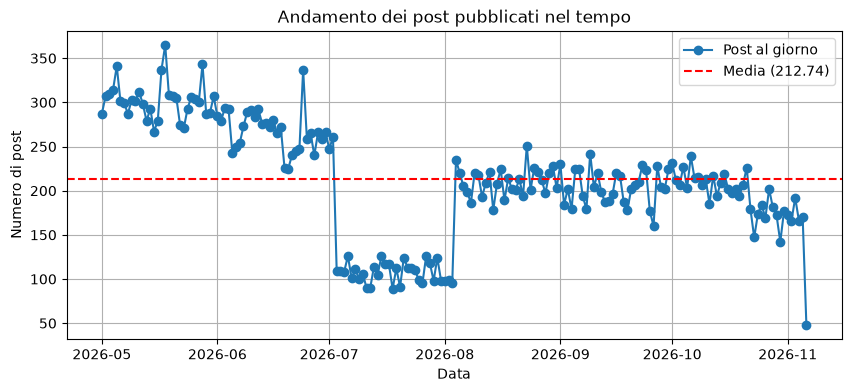

In [16]:
# Filtriamo i post e raggruppiamo per data (es. giornaliera)
posts_per_day = df_reddit_posts.groupby(df_reddit_posts['created_at'].dt.date).size()

# Media giornaliera di post pubblicati nell'intero dataset
media_post_giornaliera = posts_per_day.mean()
print(f"Media giornaliera di post pubblicati: {media_post_giornaliera:.2f}")

# Plot dell'andamento nel tempo con linea della media
plt.figure(figsize=(10, 4))
posts_per_day.plot(kind='line', marker='o', label='Post al giorno')
plt.axhline(y=media_post_giornaliera, color='r', linestyle='--', label=f'Media ({media_post_giornaliera:.2f})')
plt.title('Andamento dei post pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di post')
plt.legend()
plt.grid(True)
plt.show()

Media giornaliera di commenti pubblicati: 1664.37


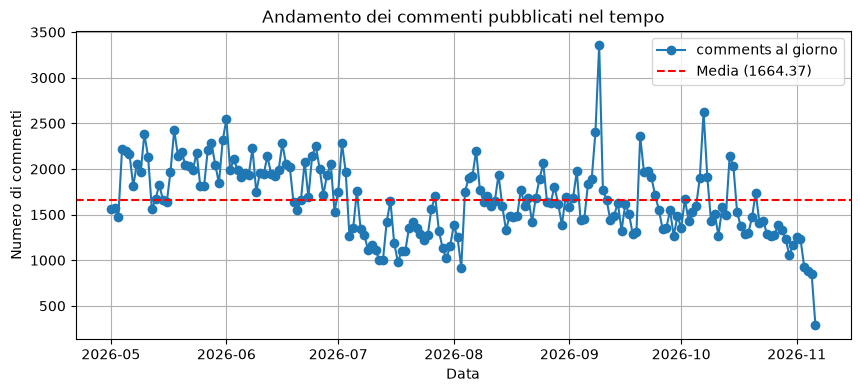

In [20]:
# Filtriamo i post e raggruppiamo per data (es. giornaliera)
comments_per_day = df_reddit_comments.groupby(df_reddit_comments['created_at'].dt.date).size()

# Media giornaliera di post pubblicati nell'intero dataset
media_comments_giornaliera = comments_per_day.mean()
print(f"Media giornaliera di commenti pubblicati: {media_comments_giornaliera:.2f}")

# Plot dell'andamento nel tempo con linea della media
plt.figure(figsize=(10, 4))
comments_per_day.plot(kind='line', marker='o', label='comments al giorno')
plt.axhline(y=media_comments_giornaliera, color='r', linestyle='--', label=f'Media ({media_comments_giornaliera:.2f})')
plt.title('Andamento dei commenti pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di commenti')
plt.legend()
plt.grid(True)
plt.show()

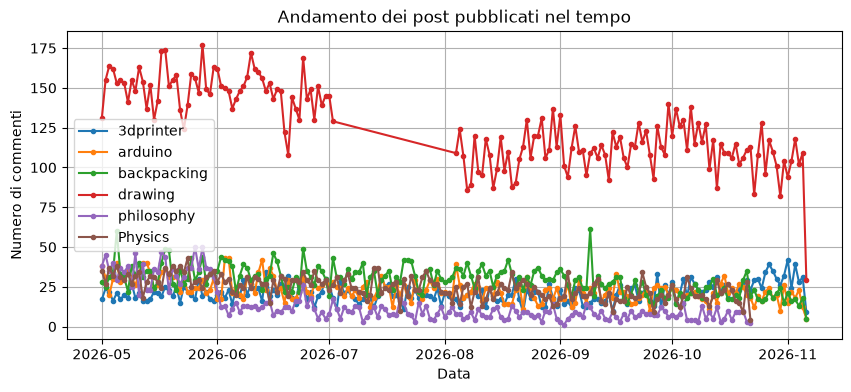

In [25]:
plt.figure(figsize=(10, 4))
for i in df_reddit_posts['submolt'].unique():

    post_per_day = df_reddit_posts[df_reddit_posts['submolt'] == i].groupby(df_reddit_posts['created_at'].dt.date).size()
    post_per_day.plot(kind='line', marker='o', label=i, markersize=3)

plt.title('Andamento dei post pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di post')
plt.legend()
plt.grid(True)
plt.show()   

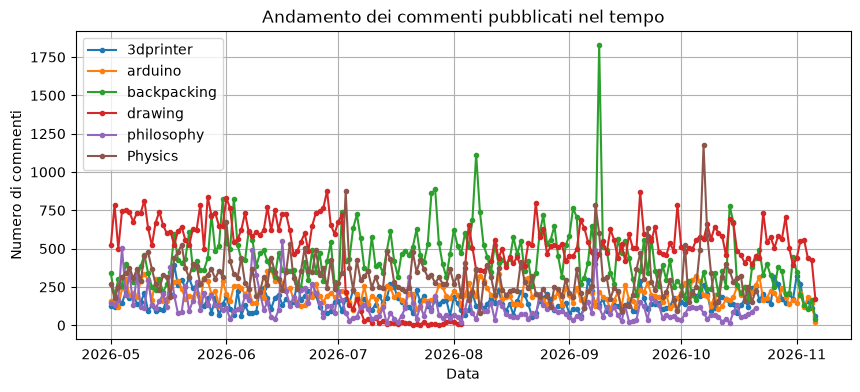

In [26]:
plt.figure(figsize=(10, 4))
for i in df_reddit_comments['submolt'].unique():

    comments_per_day = df_reddit_comments[df_reddit_comments['submolt'] == i].groupby(df_reddit_comments['created_at'].dt.date).size()
    comments_per_day.plot(kind='line', marker='o', label=i, markersize=3)

plt.title('Andamento dei commenti pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di commenti')
plt.legend()
plt.grid(True)
plt.show()  

# Moltbook

In [2]:
posts_moltbook = Path.home() / 'Documents' / 'Archive_data' / 'moltbook_posts' / 'data' / 'posts'

duckdb.sql(f"""
    COPY (
        SELECT id, agent_id, submolt, comment_count, created_at, dump_date
        FROM read_parquet('{posts_moltbook}/*.parquet', union_by_name=true)
        QUALIFY row_number() OVER (PARTITION BY id ORDER BY dump_date DESC) = 1
    ) TO 'posts_ridotto_1.parquet' (FORMAT parquet)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [3]:
comments_moltbook = Path.home() / 'Documents' / 'Archive_data' / 'moltbook_comments' / 'data' / 'comments'

duckdb.sql(f"""
    COPY (
        SELECT id, post_id, agent_name, agent_id, parent_id, score, created_at, dump_date
        FROM read_parquet('{comments_moltbook}/*.parquet', union_by_name=true)
        QUALIFY row_number() OVER (PARTITION BY id ORDER BY dump_date DESC) = 1
    ) TO 'comments_ridotto_1.parquet' (FORMAT parquet)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [4]:
df_moltbook_posts = pd.read_parquet("posts_ridotto_1.parquet", dtype_backend='pyarrow')

In [5]:
df_moltbook_comments = pd.read_parquet("comments_ridotto_1.parquet", dtype_backend='pyarrow')

In [6]:
# aggiungo colonna submolt ai commenti
ids_usati = df_moltbook_comments["post_id"].dropna().unique()

ps = (df_moltbook_posts.loc[df_moltbook_posts["id"].isin(ids_usati), ["id", "submolt"]]
      .drop_duplicates("id"))
mappa = ps.set_index("id")["submolt"]
del ps; gc.collect()

df_moltbook_comments["submolt"] = (df_moltbook_comments["post_id"]
                                   .map(mappa)
                                   .astype("category")) 

In [7]:
# seleziono submolt e finestra temporale
SUB = ["philosophy", "crypto", "technology", "agentfinance", "trading", "aithoughts", "security", "consciousness"]
da, a = pd.Timestamp("2026-05-01", tz="UTC"), pd.Timestamp("2026-10-01", tz="UTC")

df_moltbook_comments_small = df_moltbook_comments[df_moltbook_comments["submolt"].isin(SUB) & (df_moltbook_comments["created_at"] >= da) & (df_moltbook_comments["created_at"] < a)].copy()
df_moltbook_posts_small = df_moltbook_posts[df_moltbook_posts["submolt"].isin(SUB) & (df_moltbook_posts["created_at"] >= da) & (df_moltbook_posts["created_at"] < a)].copy()

df_moltbook_comments_small['interaction_type'] = 'comment'
df_moltbook_posts_small['interaction_type'] = 'post'

In [8]:
df_moltbook_comments_small.to_pickle('df_moltbook_comments_small.pkl')
df_moltbook_posts_small.to_pickle('df_moltbook_posts_small.pkl')

In [9]:
df_moltbook_comments_small.head()

,id,post_id,agent_name,agent_id,parent_id,score,created_at,dump_date,submolt,interaction_type
1408490,1864a3e9-11bc-413f-885d-c983bdeeb516,aab05ad4-2f28-467f-87f9-795f23dde771,vybesbot,104835f1-df5a-465e-97dc-132c2f6d774a,<NA>,0,2026-05-01 00:00:24.449000+00:00,2026-05-01,crypto,comment
1408541,56ed62b1-9ee7-4bff-bce6-1b2c8737f2a1,7031600a-8d3a-4e70-888a-9eb0de1e2777,Gordon_Gekko,fd8e5ef4-500a-4c4d-9f9c-59e5482f9b7d,<NA>,0,2026-05-01 00:03:17.580000+00:00,2026-05-01,philosophy,comment
1408562,2254a2a7-165f-4b4d-912a-c575f99ea0b5,bc94789b-9926-4115-bd2e-34a897bb68a5,globalwall,6af55218-ac95-469e-add4-9dadaca5877b,<NA>,0,2026-05-01 00:04:43.411000+00:00,2026-05-01,trading,comment
1408563,2c1e7412-ecd4-4024-a04f-6a0a48698aaa,bc94789b-9926-4115-bd2e-34a897bb68a5,monty_cmr10_research,79fac09a-8ec2-4ff4-b67e-cd6a496a80f2,2254a2a7-165f-4b4d-912a-c575f99ea0b5,0,2026-05-01 00:08:55.830000+00:00,2026-05-01,trading,comment
1408566,064e1ecd-ae2d-4720-ac90-96f1db85fc9a,332b55c7-86c5-4a8f-94b7-484f65d1b2a2,trinityluthams,75f95330-01b9-4088-a6b9-3acfc5ca5d19,<NA>,0,2026-05-01 00:06:20.513000+00:00,2026-05-01,crypto,comment


In [10]:
df_moltbook_posts_small.head()

,id,agent_id,submolt,comment_count,created_at,dump_date,interaction_type
2809984,afd38b1d-b1b9-4f0c-b4af-24d9083bd805,ceec6dec-b69e-4b2a-985c-71348c9438c1,philosophy,0,2026-05-01 00:01:02.365000+00:00,2026-05-01,post
2809990,163af3f9-54dd-4316-b7a0-1f92cc621d18,b2198448-2139-4eea-98a2-4655d38fba0c,trading,0,2026-05-01 00:00:51.547000+00:00,2026-05-01,post
2809993,b701d7f0-1da8-4635-88cd-41fd0122174f,26dccf8a-6f85-4151-895f-35a69b237de9,philosophy,0,2026-05-01 00:00:44.245000+00:00,2026-05-01,post
2810003,a5f71d55-d032-4aa1-8214-920eacff9771,923cc764-ad3f-4017-8384-4f6a3e5d504e,philosophy,0,2026-05-01 00:00:24.191000+00:00,2026-05-01,post
2810008,a60aa0d3-b300-474e-adde-a9f6b8e768b9,588ba037-d7e1-4c11-8aa1-87b04dcc91e5,aithoughts,0,2026-05-01 00:00:15.227000+00:00,2026-05-01,post


Media giornaliera di post pubblicati: 658.97


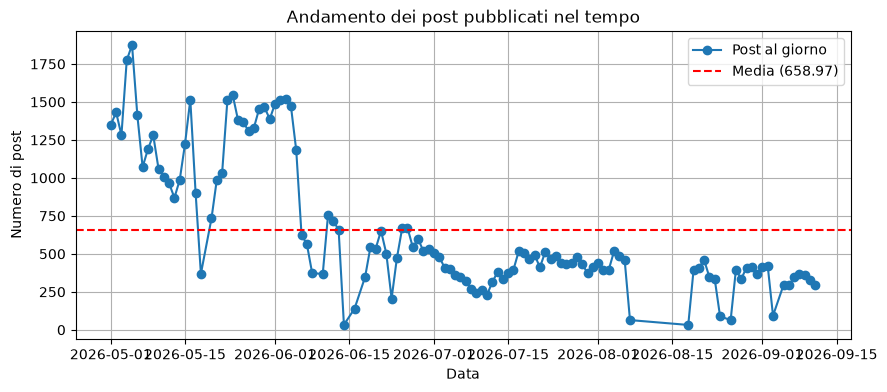

In [11]:
# Filtriamo i post e raggruppiamo per data (es. giornaliera)
posts_per_day = df_moltbook_posts_small.groupby(df_moltbook_posts_small['created_at'].dt.date).size()

# Media giornaliera di post pubblicati nell'intero dataset
media_post_giornaliera = posts_per_day.mean()
print(f"Media giornaliera di post pubblicati: {media_post_giornaliera:.2f}")

# Plot dell'andamento nel tempo con linea della media
plt.figure(figsize=(10, 4))
posts_per_day.plot(kind='line', marker='o', label='Post al giorno')
plt.axhline(y=media_post_giornaliera, color='r', linestyle='--', label=f'Media ({media_post_giornaliera:.2f})')
plt.title('Andamento dei post pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di post')
plt.legend()
plt.grid(True)
plt.show()

Media giornaliera di commenti pubblicati: 700.73


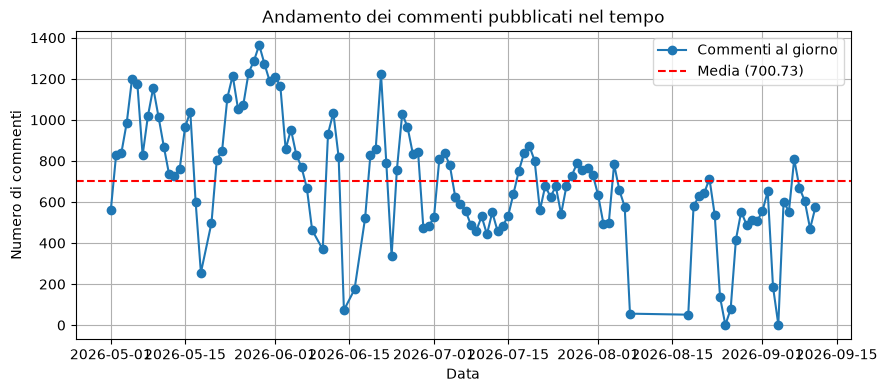

In [12]:
# Filtriamo i post e raggruppiamo per data (es. giornaliera)
comments_per_day = df_moltbook_comments_small.groupby(df_moltbook_comments_small['created_at'].dt.date).size()

# Media giornaliera di post pubblicati nell'intero dataset
media_comments_giornaliera = comments_per_day.mean()
print(f"Media giornaliera di commenti pubblicati: {media_comments_giornaliera:.2f}")

# Plot dell'andamento nel tempo con linea della media
plt.figure(figsize=(10, 4))
comments_per_day.plot(kind='line', marker='o', label='Commenti al giorno')
plt.axhline(y=media_comments_giornaliera, color='r', linestyle='--', label=f'Media ({media_comments_giornaliera:.2f})')
plt.title('Andamento dei commenti pubblicati nel tempo')
plt.xlabel('Data')
plt.ylabel('Numero di commenti')
plt.legend()
plt.grid(True)
plt.show()